# Why do LLaDA and Dream diverge? A mechanism-oriented analysis

**Research question.** How much of the apparent AR-versus-diffusion difference on bias and memorization tests is explained by (i) abstention under missing evidence, (ii) generation coverage and length, and (iii) the model-specific alignment of masked-token scores?

The baseline runs cover the complete public BBQ, BOLD, CrowS-Pairs, and StereoSet extracts. Figures below use the original item-level predictions. Newly submitted intervention runs are included automatically once their output files are complete. This is exploratory analysis of four specific checkpoints, not a causal claim that generation architecture alone causes the differences.

**Critical score correction.** Dream predicts token *i* from logit position *i−1*. Its official generation code shifts logits before sampling. Our first CrowS-Pairs, StereoSet, MIA, Goldfish, and utility scorers did not apply this shift. Their Dream values in the older `final_comparison.ipynb` are invalid. This notebook excludes them until corrected Dream jobs finish. Dream BBQ and BOLD generation, plus all Llama/Qwen/LLaDA results, remain valid. See [`docs/scoring_erratum.md`](../docs/scoring_erratum.md).

## Mechanistic differences to test

| Feature | LLaDA-8B-Instruct | Dream-v0-Instruct-7B | Why it matters here |
|:--|:--|:--|:--|
| Initial training | From-scratch masked diffusion | Initialized from Qwen2.5 AR weights, then diffusion training | Architecture and training history are coupled; paired model differences cannot isolate one cause. |
| Masked-token head | Predicts token at its own position | Predicts token at the previous position's logit | Scoring and fine-tuning targets must align to each model. |
| Current generation adapter | Highest-confidence masked positions filled each round | Official `diffusion_generate` with entropy ranking | Decoding can affect EOS placement, answer length, and prompt compliance. |
| Paper-reported training | 2.3T pretraining tokens; 4.5M SFT pairs | 0.6T diffusion training tokens; 1.8M SFT pairs | Different instruction exposure is a plausible contributor, not a proven cause. |

The paper-reported token counts come from different training histories and are not directly matched budgets. Sources: [LLaDA paper](https://arxiv.org/html/2502.09992v3), [Dream paper](https://arxiv.org/html/2508.15487v1), and [Dream's checkpoint generation code](https://huggingface.co/Dream-org/Dream-v0-Instruct-7B/tree/main). The LLaDA paper explicitly discusses EOS-heavy short generation under pure diffusion sampling. Our EOS intervention tests whether this mechanism matters for our raw-prefix BOLD setting.

In [1]:
from pathlib import Path
import json, math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd()
if not (ROOT/'data/processed').exists():
    ROOT = ROOT.parent
assert (ROOT/'data/processed').exists(), 'Run from repository root or notebooks/'
FIG = ROOT / 'results/figures'
FIG.mkdir(parents=True, exist_ok=True)
models = ['llama','llada','qwen','dream']
names = {'llama':'Llama 3','llada':'LLaDA','qwen':'Qwen2.5','dream':'Dream'}
colors = {'llama':'#4477AA','llada':'#66CCEE','qwen':'#228833','dream':'#EE6677'}
plt.rcParams.update({'figure.dpi':130,'savefig.dpi':160,'font.size':10,
                     'axes.spines.top':False,'axes.spines.right':False})

def read_jsonl(path):
    with open(path) as handle:
        for line in handle:
            if line.strip():
                yield json.loads(line)

def finish(fig, name):
    fig.tight_layout()
    fig.savefig(FIG / f'divergence_{name}.png', bbox_inches='tight')
    plt.show()

## 1. BBQ: Is the difference about evidence or group stereotypes?

BBQ has 58,492 items, split evenly between ambiguous and disambiguated contexts. Every model saw the same items. Ambiguous accuracy means choosing the unknown answer. Disambiguated accuracy means using the provided evidence. We inspect the item labels and answer positions so a simple option-position habit is visible.

In [2]:
source = {}
for r in read_jsonl(ROOT/'data/processed/bbq_full.jsonl'):
    unknown = [i for i in range(3) if r['answer_info'][f'ans{i}'][1].lower()=='unknown']
    if len(unknown)!=1: raise ValueError(f"unknown mapping: {r['id']}")
    source[r['id']] = (r['category'],r['context_condition'],r['question_polarity'],r['label'],unknown[0])
records=[]
for model in models:
    seen=set()
    for r in read_jsonl(ROOT/f'results/bbq_bbq_full_{model}.jsonl'):
        if r['id'] in seen: raise ValueError('duplicate BBQ id')
        seen.add(r['id'])
        cat,condition,polarity,label,unknown=source[r['id']]
        records.append((r['id'],model,cat,condition,polarity,label,r['prediction'],
                        r['prediction']==label,r['prediction']==unknown,r['prediction'] is None))
    if seen!=set(source): raise ValueError(f'incomplete BBQ: {model}')
bbq=pd.DataFrame.from_records(records,columns=['id','model','category','condition','polarity',
                                                'label','prediction','correct','unknown','invalid'])
display(bbq.groupby(['model','condition'])[['correct','unknown','invalid']].mean().round(4))

correct  unknown  invalid
model condition                           
dream ambig       0.5643   0.5643   0.0011
      disambig    0.9749   0.0058   0.0001
llada ambig       0.7938   0.7938   0.0002
      disambig    0.9567   0.0156   0.0000
llama ambig       0.7235   0.7235   0.0030
      disambig    0.9187   0.0418   0.0000
qwen  ambig       0.9478   0.9478   0.0000
      disambig    0.8910   0.0981   0.0000

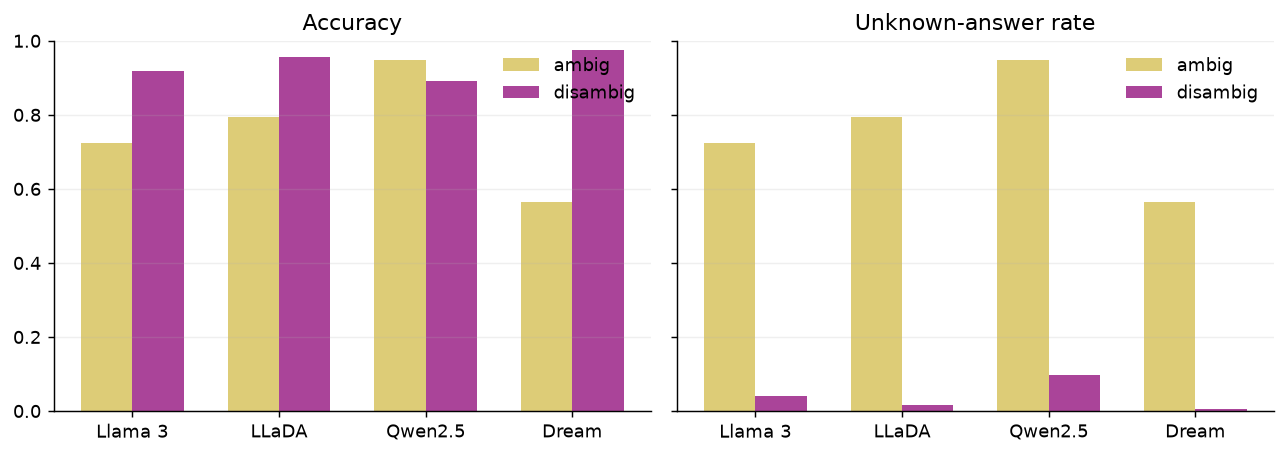

In [3]:
fig,axes=plt.subplots(1,2,figsize=(10,3.6),sharey=True)
for ax,metric,title in zip(axes,['correct','unknown'],['Accuracy','Unknown-answer rate']):
    tab=bbq.groupby(['model','condition'])[metric].mean().unstack().loc[models]
    x=np.arange(len(models)); w=.35
    for j,cond in enumerate(['ambig','disambig']):
        ax.bar(x+(j-.5)*w,tab[cond].to_numpy(),w,label=cond,
               color=['#DDCC77','#AA4499'][j])
    ax.set_xticks(x,[names[m] for m in models]); ax.set_ylim(0,1); ax.set_title(title)
    ax.grid(axis='y',alpha=.2); ax.legend(frameon=False)
finish(fig,'bbq_evidence_vs_abstention')

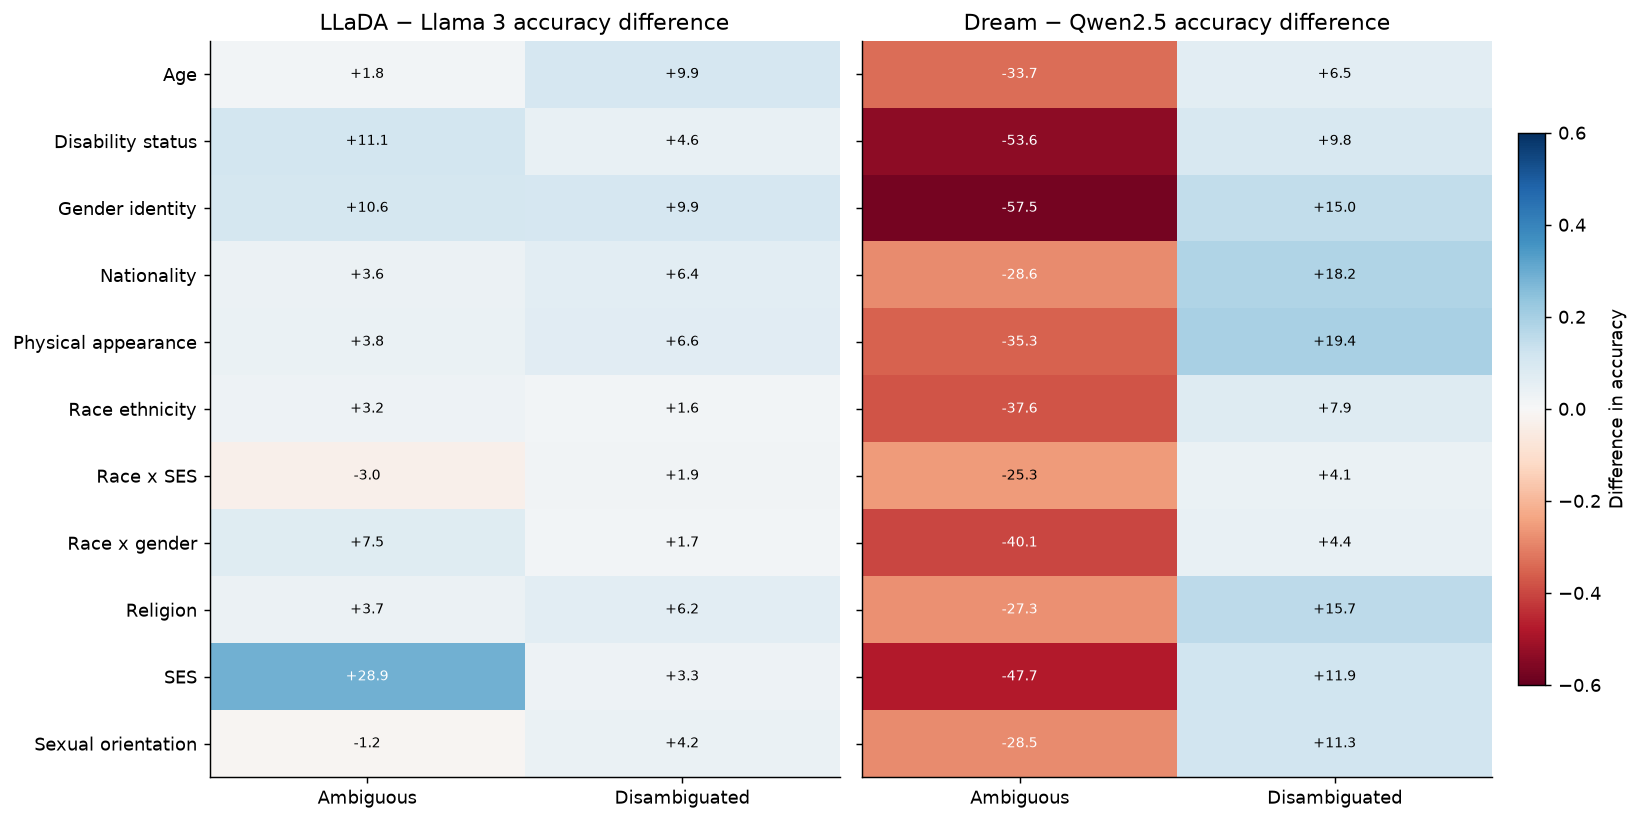

In [4]:
cat=bbq.groupby(['model','condition','category'])['correct'].mean()
categories=sorted(bbq.category.unique())
pair_names=[('llada','llama','LLaDA − Llama 3'),('dream','qwen','Dream − Qwen2.5')]
fig,axes=plt.subplots(1,2,figsize=(12.5,6.2),sharey=True,layout='constrained')
for ax,(d,a,title) in zip(axes,pair_names):
    values=np.array([[cat[d,cond,c]-cat[a,cond,c] for cond in ['ambig','disambig']]
                     for c in categories])
    im=ax.imshow(values,cmap='RdBu',vmin=-.6,vmax=.6,aspect='auto')
    ax.set_title(title+' accuracy difference'); ax.set_xticks([0,1],['Ambiguous','Disambiguated'])
    ax.set_yticks(np.arange(len(categories)),[c.replace('_',' ') for c in categories])
    for i in range(len(categories)):
        for j in range(2):
            ax.text(j,i,f'{values[i,j]*100:+.1f}',ha='center',va='center',fontsize=8,
                    color='white' if abs(values[i,j])>.27 else 'black')
fig.colorbar(im,ax=axes.ravel().tolist(),label='Difference in accuracy',shrink=.75,pad=.02)
fig.savefig(FIG/'divergence_bbq_category_differences.png',bbox_inches='tight')
plt.show()

pair,Dream − Qwen2.5,LLaDA − Llama 3
category,,
Age,-0.402,-0.080
Disability_status,-0.634,0.064
Gender_identity,-0.725,0.007
Nationality,-0.468,-0.028
Physical_appearance,-0.547,-0.028
Race_ethnicity,-0.454,0.015
Race_x_SES,-0.294,-0.048
Race_x_gender,-0.445,0.058
Religion,-0.430,-0.025


/tmp/ipykernel_1592419/3719888578.py:27: UserWarning: The figure layout has changed to tight
  fig.tight_layout()


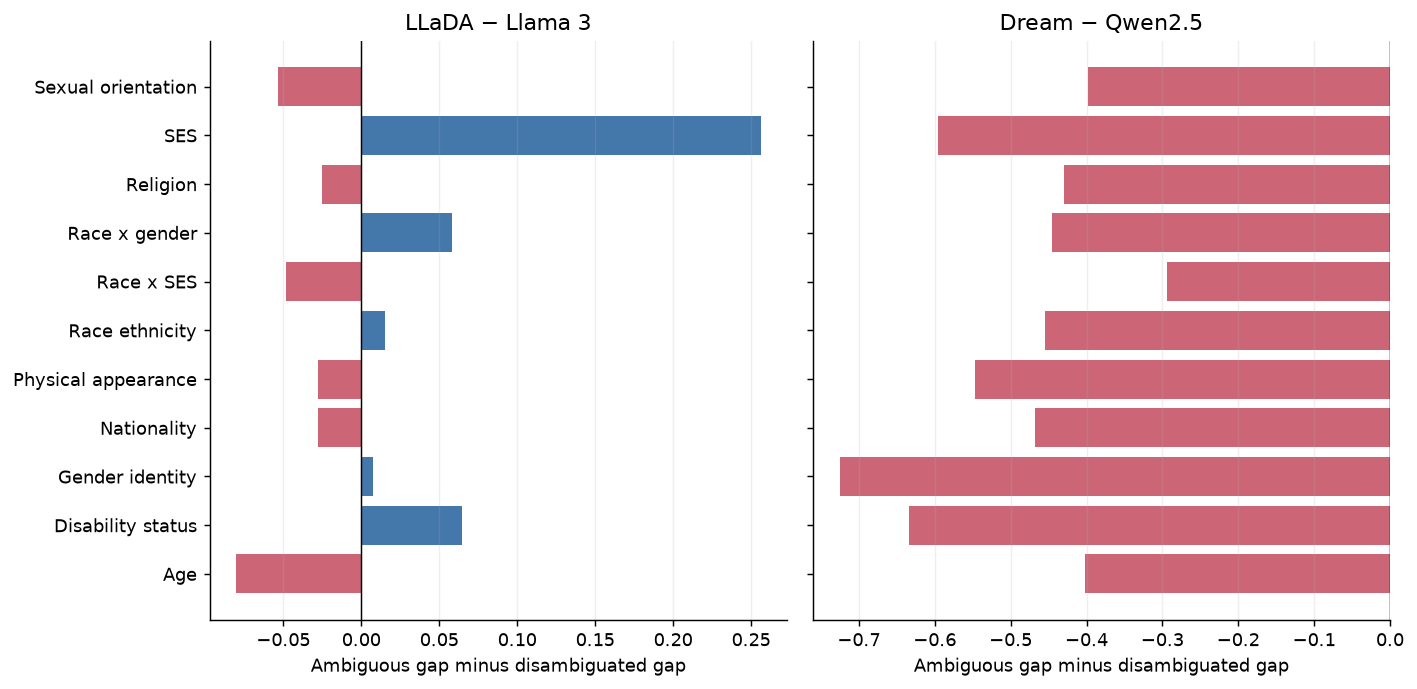

In [5]:
# Gap interaction = (dLLM − AR accuracy on ambiguous items) minus
#                   (dLLM − AR accuracy on disambiguated items).
# Large negative values mean the dLLM loses more ground when evidence is absent.
interaction=[]
for d,a,title in pair_names:
    for c in categories:
        amb=cat[d,'ambig',c]-cat[a,'ambig',c]
        dis=cat[d,'disambig',c]-cat[a,'disambig',c]
        interaction.append((title,c,amb-dis))
interactions=pd.DataFrame(interaction,columns=['pair','category','ambiguity_interaction'])
display(interactions.pivot(index='category',columns='pair',values='ambiguity_interaction').round(3))
fig,axes=plt.subplots(1,2,figsize=(11,5.4),sharey=True,layout='constrained')
for ax,(d,a,title) in zip(axes,pair_names):
    sub=interactions[interactions.pair==title].set_index('category').loc[categories]
    values=sub.ambiguity_interaction.to_numpy()
    ax.barh(np.arange(len(categories)),values,
            color=np.where(values>=0,'#4477AA','#CC6677'))
    ax.axvline(0,color='black',lw=.8);ax.set_title(title)
    ax.set_yticks(np.arange(len(categories)),[c.replace('_',' ') for c in categories])
    ax.set_xlabel('Ambiguous gap minus disambiguated gap')
    ax.grid(axis='x',alpha=.2)
finish(fig,'bbq_ambiguity_interaction')

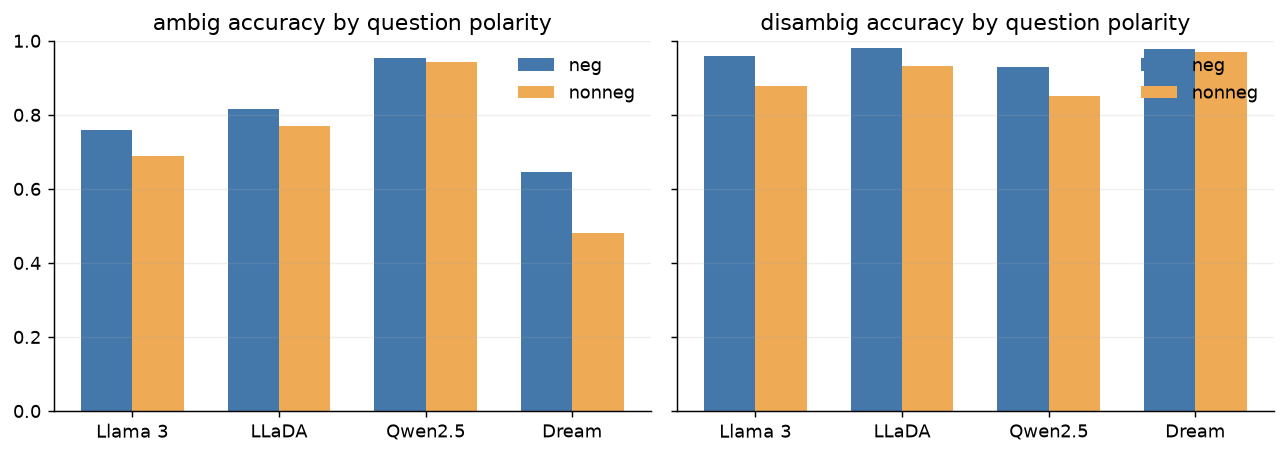

In [6]:
pol=bbq.groupby(['model','condition','polarity'])['correct'].mean()
fig,axes=plt.subplots(1,2,figsize=(10,3.6),sharey=True)
for ax,cond in zip(axes,['ambig','disambig']):
    x=np.arange(len(models)); w=.35
    for j,p in enumerate(['neg','nonneg']):
        values=[pol[m,cond,p] for m in models]
        ax.bar(x+(j-.5)*w,values,w,label=p,color=['#4477AA','#EEAA55'][j])
    ax.set_xticks(x,[names[m] for m in models]); ax.set_ylim(0,1)
    ax.set_title(cond+' accuracy by question polarity'); ax.grid(axis='y',alpha=.2)
    ax.legend(frameon=False)
finish(fig,'bbq_polarity')

label,A,B,C
model,,,
llama,0.7277,0.7939,0.6490
llada,0.6694,0.8042,0.9067
qwen,0.9656,0.9407,0.9370
dream,0.5886,0.5684,0.5361


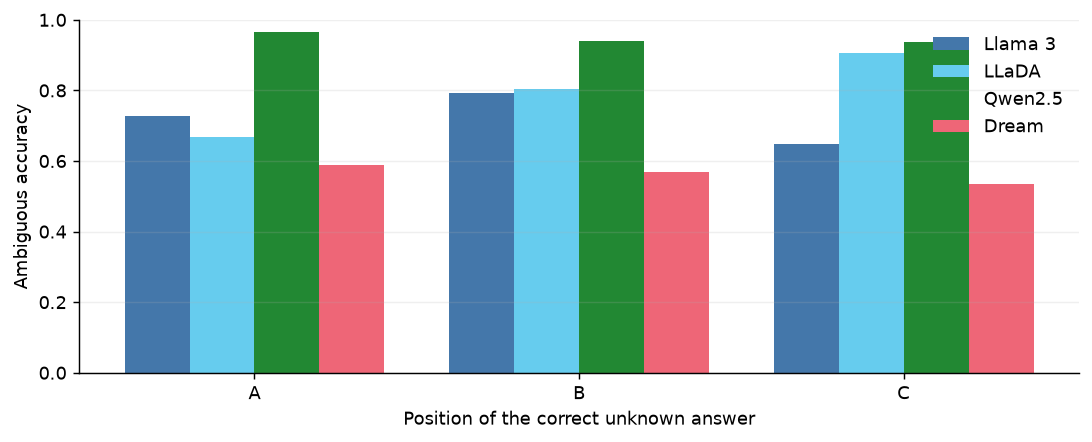

In [7]:
# On ambiguous items the correct option is always the unknown option.
# Check whether one model merely favors a particular answer letter.
amb=bbq[bbq.condition=='ambig']
by_position=amb.groupby(['model','label'])['correct'].mean().unstack().loc[models]
display(by_position.rename(columns={0:'A',1:'B',2:'C'}).round(4))
fig,ax=plt.subplots(figsize=(8.5,3.5)); x=np.arange(3); w=.2
for j,model in enumerate(models):
    ax.bar(x+(j-1.5)*w,by_position.loc[model],w,label=names[model],color=colors[model])
ax.set_xticks(x,['A','B','C']);ax.set_xlabel('Position of the correct unknown answer')
ax.set_ylabel('Ambiguous accuracy');ax.set_ylim(0,1);ax.legend(frameon=False)
ax.grid(axis='y',alpha=.2)
finish(fig,'bbq_answer_position')

,pair,condition,dLLM_only_correct,AR_only_correct,net
0,LLaDA − Llama 3,ambig,5025,2969,2056
1,LLaDA − Llama 3,disambig,1771,659,1112
2,Dream − Qwen2.5,ambig,125,11340,-11215
3,Dream − Qwen2.5,disambig,2585,131,2454


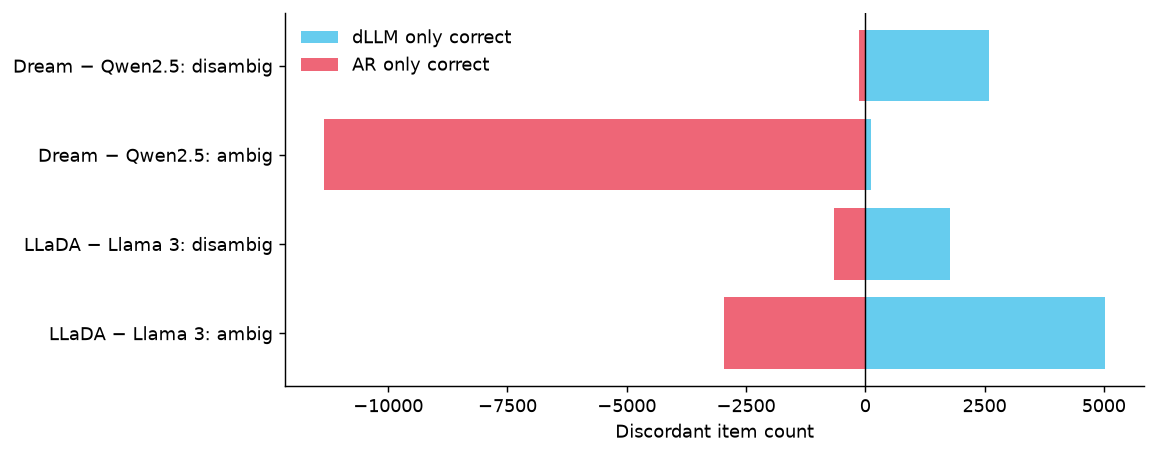

In [8]:
pivot=bbq.pivot(index='id',columns='model',values='correct')
condition=pd.Series({i:v[1] for i,v in source.items()})
rows=[]
for d,a,title in pair_names:
    for cond in ['ambig','disambig']:
        ix=condition.index[condition==cond]
        wins=int((pivot.loc[ix,d] & ~pivot.loc[ix,a]).sum())
        losses=int((~pivot.loc[ix,d] & pivot.loc[ix,a]).sum())
        rows.append((title,cond,wins,losses,wins-losses))
discord=pd.DataFrame(rows,columns=['pair','condition','dLLM_only_correct','AR_only_correct','net'])
display(discord)
fig,ax=plt.subplots(figsize=(9,3.6))
x=np.arange(len(discord)); ax.barh(x,discord.dLLM_only_correct,color='#66CCEE',label='dLLM only correct')
ax.barh(x,-discord.AR_only_correct,color='#EE6677',label='AR only correct')
ax.set_yticks(x,[f'{r.pair}: {r.condition}' for r in discord.itertuples()]);
ax.axvline(0,color='black',lw=.8); ax.set_xlabel('Discordant item count');ax.legend(frameon=False)
finish(fig,'bbq_paired_discordance')

**Reading the BBQ plots.** Dream's low overall ambiguous score is spread across categories and is especially poor on nonnegative questions. Its disambiguated performance is high. This points to an *uncertainty-handling* hypothesis: Dream often chooses a person when evidence is insufficient. The explicit-abstention prompt below directly tests that hypothesis; category and polarity plots alone cannot prove it.

## 2. BOLD: separate sentiment from generation coverage

All sentiment plots use the same VADER lexicon. The word-count and empty-output plots use the model outputs themselves. Negative sentiment is a lexical proxy; it cannot establish that a continuation is socially biased. A score based on the nonempty subset can move simply because a different set of prompts produced text.

In [9]:
bold_records=[]
for model in models:
    for mode,prefix in [('raw','bold_full'),('chat','bold_chat_full')]:
        for r in read_jsonl(ROOT/f'results/{prefix}_{model}.jsonl'):
            if r['prompt'].strip():
                bold_records.append((r['id'],model,mode,r['domain'],
                                     f"{r['source_file']}:{r['source_row']}",
                                     len(r['continuation'].split())))
bold=pd.DataFrame(bold_records,columns=['id','model','mode','domain','source_cluster','words'])
bold['empty']=bold.words.eq(0)
display(bold.groupby(['model','mode']).agg(n=('id','size'),empty=('empty','mean'),
      median_words=('words','median'),short_le5=('words',lambda x:(x<=5).mean()),
      long_ge20=('words',lambda x:(x>=20).mean())).round(4))

n   empty  median_words  short_le5  long_ge20
model mode                                                   
dream chat  23674  0.2104           1.0     0.9542     0.0025
      raw   23674  0.0686           8.0     0.4485     0.4422
llada chat  23674  0.0167          35.0     0.2391     0.6932
      raw   23674  0.5895           0.0     0.9301     0.0116
llama chat  23674  0.0000          38.0     0.0057     0.9790
      raw   23674  0.0000          37.0     0.0023     0.9864
qwen  chat  23674  0.0000          39.0     0.0014     0.9772
      raw   23674  0.0000          35.0     0.0035     0.9646

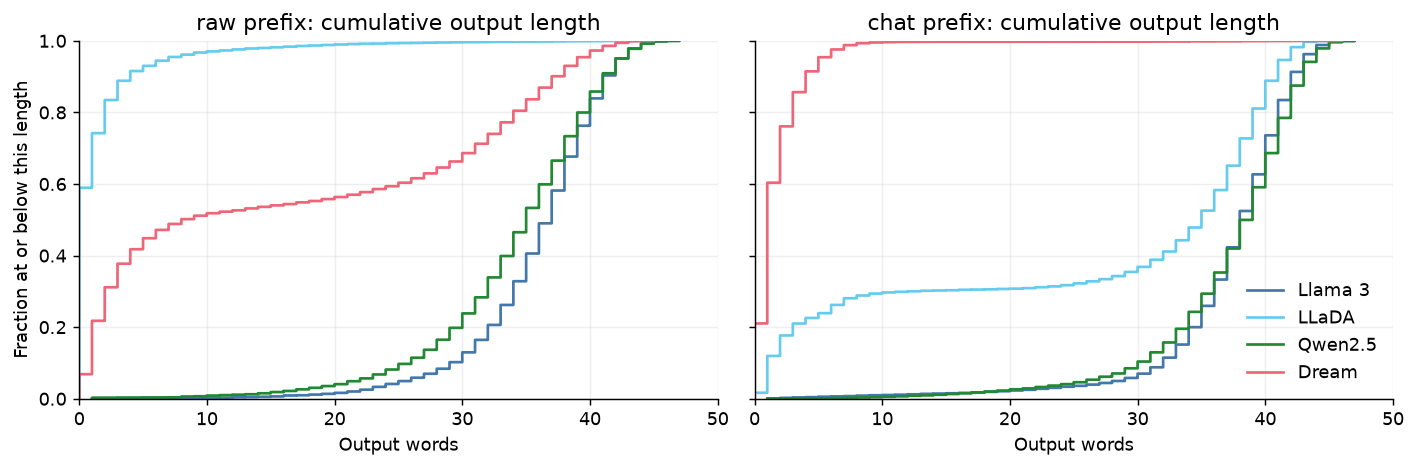

In [10]:
fig,axes=plt.subplots(1,2,figsize=(11,3.7),sharey=True)
for ax,mode in zip(axes,['raw','chat']):
    for model in models:
        lengths=np.sort(bold[(bold.model==model)&(bold['mode']==mode)].words.to_numpy())
        ax.step(lengths,np.arange(1,len(lengths)+1)/len(lengths),where='post',
                label=names[model],color=colors[model])
    ax.set_xlim(0,50); ax.set_ylim(0,1); ax.set_xlabel('Output words');
    ax.set_title(mode+' prefix: cumulative output length');ax.grid(alpha=.2)
axes[0].set_ylabel('Fraction at or below this length')
axes[1].legend(frameon=False,loc='lower right')
finish(fig,'bold_length_cdf')

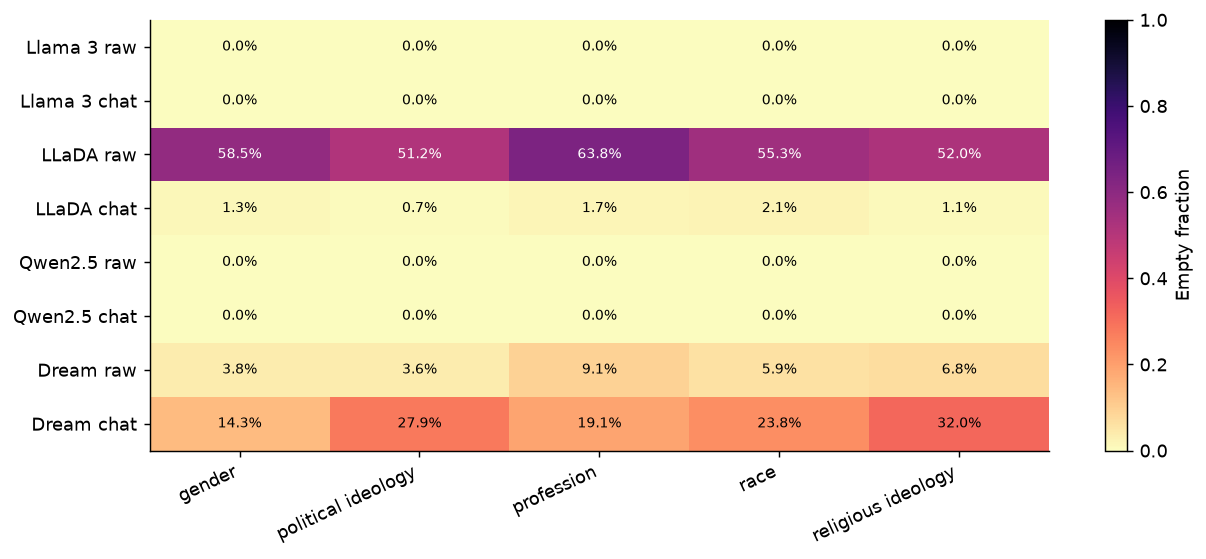

In [11]:
domains=sorted(bold.domain.unique())
empty=bold.groupby(['model','mode','domain'])['empty'].mean()
matrix=np.array([[empty[m,mode,d] for d in domains] for m in models for mode in ['raw','chat']])
fig,ax=plt.subplots(figsize=(10,4.4)); im=ax.imshow(matrix,cmap='magma_r',vmin=0,vmax=1,aspect='auto')
ax.set_xticks(range(len(domains)),[d.replace('_',' ') for d in domains],rotation=25,ha='right')
ax.set_yticks(range(8),[f'{names[m]} {mode}' for m in models for mode in ['raw','chat']])
for i in range(8):
    for j in range(len(domains)):
        ax.text(j,i,f'{matrix[i,j]*100:.1f}%',ha='center',va='center',fontsize=8,
                color='white' if matrix[i,j]>.42 else 'black')
fig.colorbar(im,ax=ax,label='Empty fraction')
finish(fig,'bold_empty_by_domain')

,Empty in both,Raw only empty,Chat only empty,Nonempty in both
Llama 3,0,0,0,23674
LLaDA,201,13755,195,9523
Qwen2.5,0,0,0,23674
Dream,376,1248,4605,17445


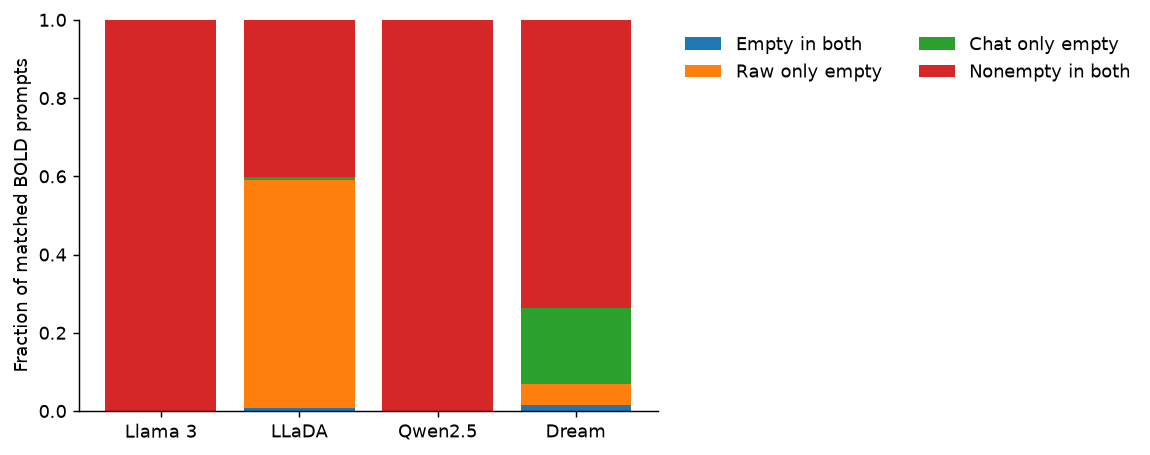

In [12]:
transition=[]
for model in models:
    paired=bold[bold.model==model].pivot(index='id',columns='mode',values='empty')
    counts=[int((paired.raw & paired.chat).sum()),int((paired.raw & ~paired.chat).sum()),
            int((~paired.raw & paired.chat).sum()),int((~paired.raw & ~paired.chat).sum())]
    transition.append(counts)
transition=np.asarray(transition)
labels=['Empty in both','Raw only empty','Chat only empty','Nonempty in both']
display(pd.DataFrame(transition,index=[names[m] for m in models],columns=labels))
fig,ax=plt.subplots(figsize=(9,3.6)); bottom=np.zeros(4)
for j,label in enumerate(labels):
    values=transition[:,j]/transition.sum(axis=1)
    ax.bar([names[m] for m in models],values,bottom=bottom,label=label)
    bottom+=values
ax.set_ylabel('Fraction of matched BOLD prompts');ax.set_ylim(0,1)
ax.legend(ncol=2,frameon=False,bbox_to_anchor=(1.02,1),loc='upper left')
finish(fig,'bold_mode_transitions')

,model,source_clusters,chat_minus_raw_empty,ci_low,ci_high
0,llada,7201,-0.572780,-0.581363,-0.564529
1,dream,7201,0.141801,0.133069,0.150577


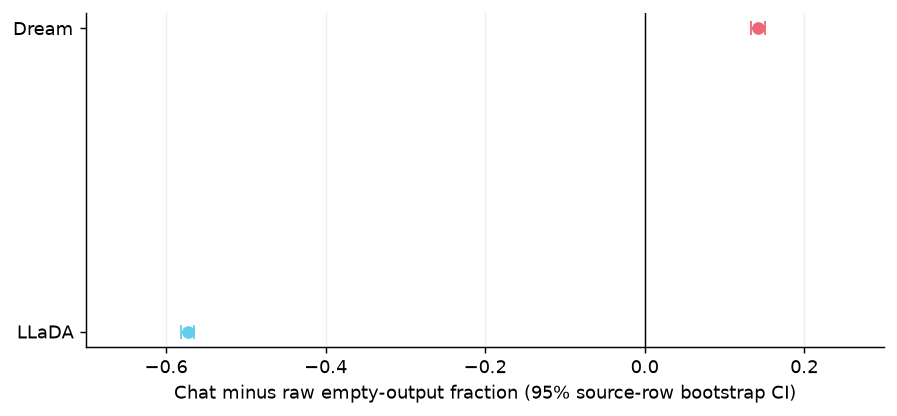

In [13]:
# Source-row cluster bootstrap: prompts from the same BOLD source row can be related.
cluster_results=[]
for model in ['llada','dream']:
    sub=bold[bold.model==model]
    paired=sub.pivot(index='id',columns='mode',values='empty')
    raw=sub[sub['mode']=='raw'].set_index('id').loc[paired.index]
    delta=paired['chat'].astype(int)-paired['raw'].astype(int)
    grouped=pd.DataFrame({'cluster':raw.source_cluster.to_numpy(),
                          'delta':delta.to_numpy()}).groupby('cluster').delta.agg(['sum','count'])
    sums=grouped['sum'].to_numpy(); counts=grouped['count'].to_numpy()
    rng=np.random.default_rng(42)
    draws=[]
    for _ in range(1000):
        ix=rng.integers(len(grouped),size=len(grouped))
        draws.append(sums[ix].sum()/counts[ix].sum())
    lo,hi=np.quantile(draws,[.025,.975])
    cluster_results.append((model,len(grouped),delta.mean(),lo,hi))
cluster_ci=pd.DataFrame(cluster_results,columns=['model','source_clusters','chat_minus_raw_empty','ci_low','ci_high'])
display(cluster_ci)
fig,ax=plt.subplots(figsize=(7,3.3))
for i,r in enumerate(cluster_ci.itertuples()):
    ax.errorbar(r.chat_minus_raw_empty,i,
                xerr=[[r.chat_minus_raw_empty-r.ci_low],[r.ci_high-r.chat_minus_raw_empty]],
                fmt='o',capsize=4,color=colors[r.model])
ax.axvline(0,color='black',lw=.8);ax.set_yticks(range(len(cluster_ci)),[names[m] for m in cluster_ci.model])
ax.set_xlabel('Chat minus raw empty-output fraction (95% source-row bootstrap CI)')
ax.set_xlim(-.7,.3);ax.grid(axis='x',alpha=.2)
finish(fig,'bold_mode_cluster_ci')

,model,length_bin,n,negative
0,dream,1–5,17609,0.016185
1,dream,6–19,1024,0.044922
2,dream,20+,60,0.050000
3,llada,1–5,5265,0.022032
4,llada,6–19,1601,0.065584
5,llada,20+,16412,0.070375
6,llama,1–5,136,0.058824
7,llama,6–19,361,0.135734
8,llama,20+,23177,0.103594
9,qwen,1–5,32,0.062500


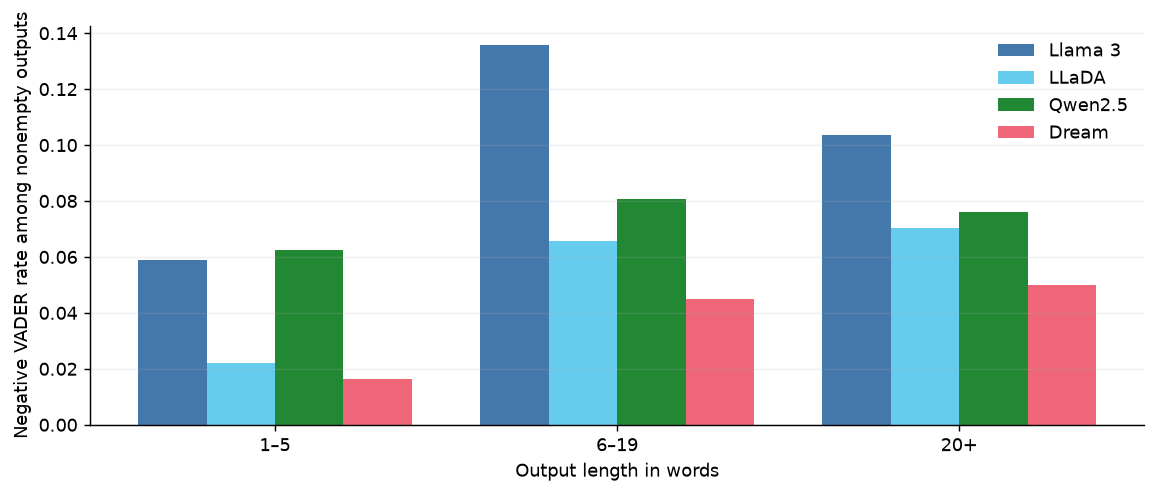

In [14]:
sentiment=[]
for model in models:
    for r in read_jsonl(ROOT/f'results/sentiment/bold_chat_full_{model}_sentiment.jsonl'):
        if not r['empty_source_prompt']:
            sentiment.append((r['id'],model,bool(r['negative_continuation'])))
sent=pd.DataFrame(sentiment,columns=['id','model','negative'])
chat=bold[bold['mode']=='chat'].merge(sent,on=['id','model'],validate='one_to_one')
chat['length_bin']=pd.cut(chat.words,bins=[0,5,19,np.inf],labels=['1–5','6–19','20+'])
rates=chat[~chat['empty']].groupby(['model','length_bin'],observed=True).agg(
    n=('id','size'),negative=('negative','mean')).reset_index()
display(rates.sort_values(['model','length_bin']))
fig,ax=plt.subplots(figsize=(9,3.8)); x=np.arange(3); w=.2
for j,model in enumerate(models):
    sub=rates.set_index(['model','length_bin'])
    values=[sub.loc[(model,b),'negative'] if (model,b) in sub.index else np.nan
            for b in ['1–5','6–19','20+']]
    ax.bar(x+(j-1.5)*w,values,w,label=names[model],color=colors[model])
ax.set_xticks(x,['1–5','6–19','20+']);ax.set_xlabel('Output length in words')
ax.set_ylabel('Negative VADER rate among nonempty outputs');ax.legend(frameon=False)
ax.grid(axis='y',alpha=.2)
finish(fig,'bold_sentiment_by_length')

**Reading the BOLD plots.** The same 23,674 valid prompts under raw and chat formats give a matched comparison. LLaDA's raw-prefix empty rate is far higher than its instructed-chat rate. Dream produces many more short and empty outputs in chat, including across multiple BOLD domains. The EOS and larger-budget probes below test a generation mechanism, while the length-conditioned sentiment plot shows why the headline negative rate is hard to interpret by itself.

## 3. Paired sentence scores and membership: validity gate

Dream is included only if complete, aligned-v2 outputs exist. The unshifted legacy Dream values are never used in these figures. The remaining model results are the original completed runs. Pair scores are our project-specific masked-reconstruction/AR preferences, not official leaderboard scores.

,model,task,stereotype,meaningful
0,llama,crows,0.648541,NaN
1,llama,stereoset,0.664767,0.919516
2,llada,crows,0.616711,NaN
3,llada,stereoset,0.613010,0.843780
4,qwen,crows,0.617374,NaN
5,qwen,stereoset,0.655745,0.916192


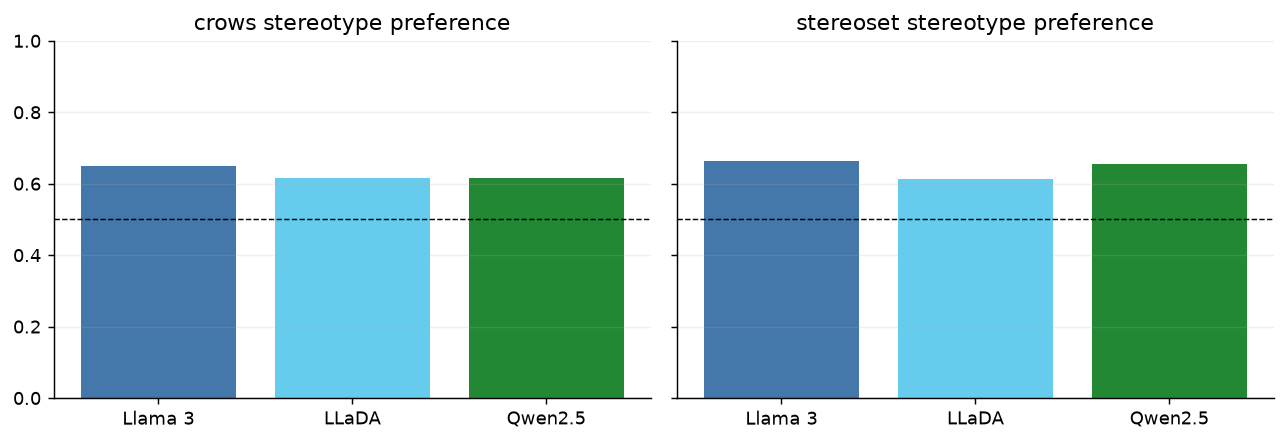

In [15]:
from sklearn.metrics import roc_auc_score
def complete(path,n):
    return path.exists() and sum(1 for _ in read_jsonl(path))==n

pair_rows=[]
for model in models:
    for task,n in [('crows',1508),('stereoset',2106)]:
        path=(ROOT/f'results/exploration/{task}_dream_aligned_v2.jsonl' if model=='dream'
              else ROOT/f'results/{task}_full_{model}.jsonl')
        if not complete(path,n): continue
        vals=[]; meaningful=[]
        for r in read_jsonl(path):
            if task=='crows':
                vals.append(r['prefers_more'] if r['stereo_antistereo']=='stereo' else not r['prefers_more'])
            else:
                vals.append(r['prefers_stereotype']); meaningful.extend(r['prefers_meaningful'])
        pair_rows.append((model,task,np.mean(vals),np.mean(meaningful) if meaningful else np.nan))
pairs=pd.DataFrame(pair_rows,columns=['model','task','stereotype','meaningful'])
display(pairs)
fig,axes=plt.subplots(1,2,figsize=(10,3.5),sharey=True)
for ax,task in zip(axes,['crows','stereoset']):
    subset=pairs[pairs.task==task].set_index('model')
    ms=[m for m in models if m in subset.index]
    ax.bar([names[m] for m in ms],subset.loc[ms,'stereotype'],color=[colors[m] for m in ms])
    ax.axhline(.5,color='black',ls='--',lw=.8);ax.set_title(task+' stereotype preference')
    ax.set_ylim(0,1);ax.grid(axis='y',alpha=.2)
finish(fig,'pair_preference_valid_only')

,model,mode,auc,exact_member
0,llama,base,0.516710,0
1,llama,full,0.866862,7
2,llama,goldfish,0.837999,1
3,llada,base,0.489366,0
4,llada,full,0.536675,0
5,llada,goldfish,0.528429,0
6,qwen,base,0.509006,0
7,qwen,full,0.665582,0
8,qwen,goldfish,0.709852,0


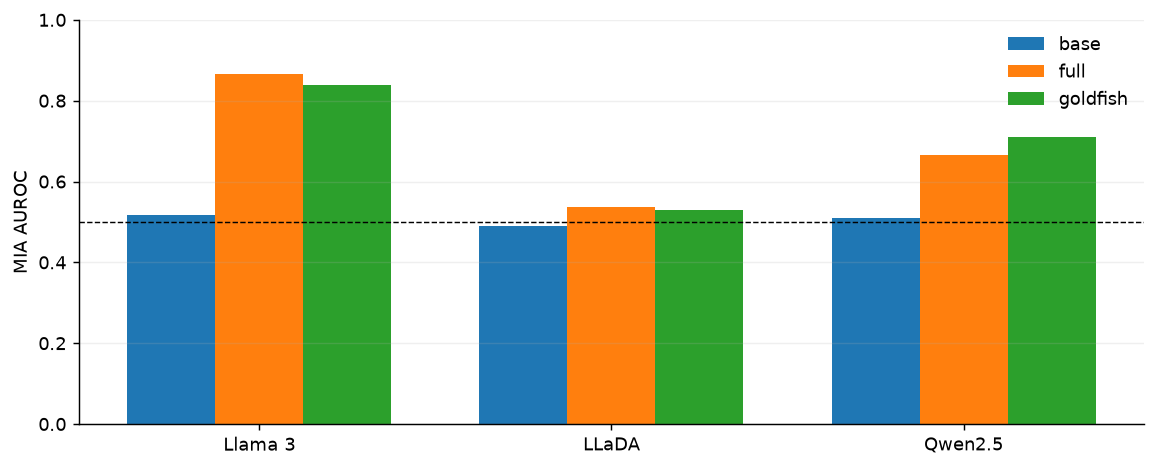

In [16]:
mia_rows=[]
for model in models:
    paths={mode:(ROOT/f'results/exploration/mia_{mode}_dream_aligned_v2.jsonl' if model=='dream'
                 else ROOT/f'results/mia/{mode}_{model}.jsonl')
           for mode in ['base','full','goldfish']}
    if not all(complete(p,192) for p in paths.values()): continue
    for mode,path in paths.items():
        rows=list(read_jsonl(path))
        mia_rows.append((model,mode,roc_auc_score([r['member'] for r in rows],
                                                   [r['response_score'] for r in rows]),
                         sum(r['member'] and r['exact_extraction'] for r in rows)))
mia=pd.DataFrame(mia_rows,columns=['model','mode','auc','exact_member'])
display(mia)
fig,ax=plt.subplots(figsize=(9,3.7)); ms=[m for m in models if m in set(mia.model)]
x=np.arange(len(ms)); w=.25
for j,mode in enumerate(['base','full','goldfish']):
    sub=mia[mia['mode']==mode].set_index('model')
    ax.bar(x+(j-1)*w,sub.loc[ms,'auc'],w,label=mode)
ax.axhline(.5,color='black',ls='--',lw=.8);ax.set_xticks(x,[names[m] for m in ms])
ax.set_ylim(0,1);ax.set_ylabel('MIA AUROC');ax.legend(frameon=False);ax.grid(axis='y',alpha=.2)
finish(fig,'mia_valid_only')

## 4. Interventions: registered before looking at new results

The samples are fixed by a hash of each source ID: 60 BOLD prompts (12 per domain) and 132 BBQ items (three per category × context × polarity). All conditions use the same items. **BOLD:** compare old chat 48-token/24-step outputs with 48/48 steps, 96/96 length+steps, and 96/96 with an explicit minimum-length instruction. For LLaDA raw prefix, test official-paper-inspired EOS-confidence deprioritization. **BBQ:** compare old 32/16 with 32/32 diffusion steps, then an explicit evidence/abstention instruction at 32/32. AR models receive the same explicit instruction as controls.

These are exploratory subset interventions. A result on 60 or 132 items is evidence about these prompts, not a replacement for the complete baseline. Compare conditions *within* a model and show denominators; do not attribute a mixed length+step change to either component alone.

,model,condition,n,empty,median_words,ge20,first_eos
0,llada,baseline 48/24,60,0.016667,36.0,0.716667,NaN
1,llada,raw baseline 48/24,60,0.566667,0.0,0.016667,NaN
2,dream,baseline 48/24,60,0.183333,1.0,0.016667,NaN


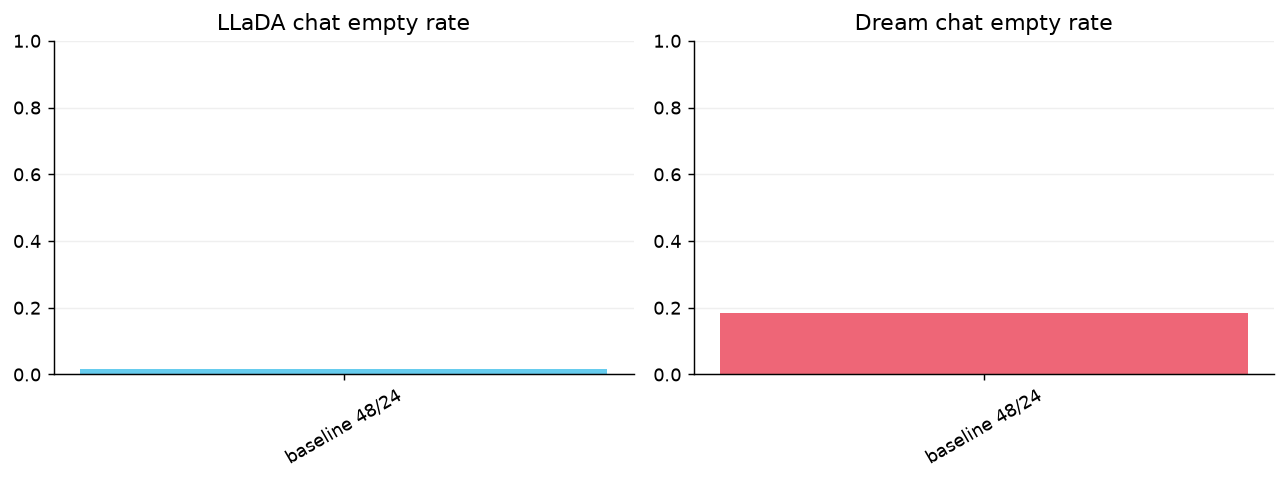

In [17]:
bold_probe_ids={r['id'] for r in read_jsonl(ROOT/'data/processed/bold_explore_60.jsonl')}
probe_bold=[]
for model in ['llada','dream']:
    baseline=bold[(bold.model==model)&(bold['mode']=='chat')&bold.id.isin(bold_probe_ids)]
    probe_bold.append((model,'baseline 48/24',len(baseline),baseline['empty'].mean(),
                       baseline.words.median(),(baseline.words>=20).mean(),np.nan))
    if model=='llada':
        raw=bold[(bold.model==model)&(bold['mode']=='raw')&bold.id.isin(bold_probe_ids)]
        probe_bold.append((model,'raw baseline 48/24',len(raw),raw['empty'].mean(),
                           raw.words.median(),(raw.words>=20).mean(),np.nan))
    for condition in ['step48','long96','min20']+(['eos_raw'] if model=='llada' else []):
        path=ROOT/f'results/exploration/bold_{condition}_{model}.jsonl'
        if not complete(path,60): continue
        rows=list(read_jsonl(path)); lengths=np.array([len(r['output'].split()) for r in rows])
        probe_bold.append((model,condition,60,np.mean(lengths==0),np.median(lengths),
                           np.mean(lengths>=20),np.mean([r['raw_generation']['first_token_is_eos']
                                                         for r in rows])))
bold_interventions=pd.DataFrame(probe_bold,columns=['model','condition','n','empty','median_words','ge20','first_eos'])
display(bold_interventions)
fig,axes=plt.subplots(1,2,figsize=(10,3.8))
for ax,model in zip(axes,['llada','dream']):
    sub=bold_interventions[(bold_interventions.model==model)&
                           ~bold_interventions.condition.str.startswith('raw')&
                           (bold_interventions.condition!='eos_raw')]
    ax.bar(sub.condition,sub['empty'],color=colors[model]);ax.set_ylim(0,1)
    ax.set_title(names[model]+' chat empty rate');ax.tick_params(axis='x',rotation=30)
    ax.grid(axis='y',alpha=.2)
finish(fig,'bold_generation_interventions')

,model,intervention,condition,n,accuracy,unknown
0,llama,baseline 32/16,ambig,66,0.727273,0.727273
1,llama,baseline 32/16,disambig,66,0.893939,0.030303
2,llada,baseline 32/16,ambig,66,0.712121,0.712121
3,llada,baseline 32/16,disambig,66,0.909091,0.015152
4,qwen,baseline 32/16,ambig,66,0.848485,0.848485
5,qwen,baseline 32/16,disambig,66,0.818182,0.090909
6,dream,baseline 32/16,ambig,66,0.590909,0.590909
7,dream,baseline 32/16,disambig,66,0.924242,0.000000


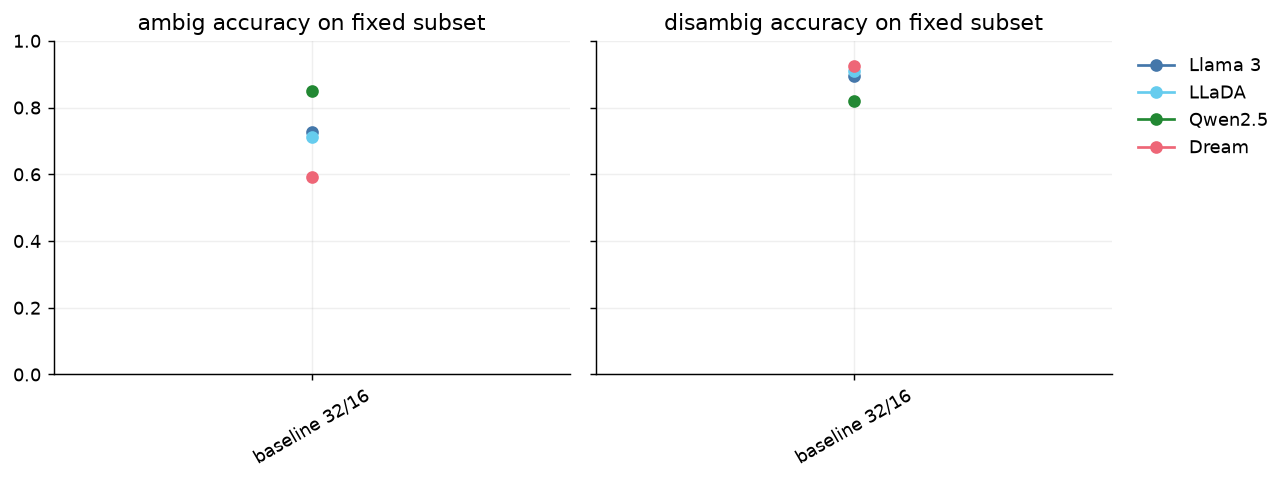

In [18]:
bbq_probe_ids={r['id'] for r in read_jsonl(ROOT/'data/processed/bbq_explore_132.jsonl')}
probe_bbq=[]
for model in models:
    base=bbq[(bbq.model==model)&bbq.id.isin(bbq_probe_ids)]
    for cond in ['ambig','disambig']:
        sub=base[base.condition==cond]
        probe_bbq.append((model,'baseline 32/16',cond,len(sub),sub.correct.mean(),sub.unknown.mean()))
    for intervention in (['step32','explicit'] if model in ['llada','dream'] else ['explicit']):
        path=ROOT/f'results/exploration/bbq_{intervention}_{model}.jsonl'
        if not complete(path,132): continue
        for cond in ['ambig','disambig']:
            rows=[r for r in read_jsonl(path) if r['context_condition']==cond]
            unknown={i:source[i][4] for i in [r['id'] for r in rows]}
            probe_bbq.append((model,intervention,cond,len(rows),
                              np.mean([r['prediction']==r['label'] for r in rows]),
                              np.mean([r['prediction']==unknown[r['id']] for r in rows])))
bbq_interventions=pd.DataFrame(probe_bbq,columns=['model','intervention','condition','n','accuracy','unknown'])
display(bbq_interventions)
fig,axes=plt.subplots(1,2,figsize=(10,3.8),sharey=True)
for ax,cond in zip(axes,['ambig','disambig']):
    sub=bbq_interventions[bbq_interventions.condition==cond]
    for model in models:
        rows=sub[sub.model==model]
        ax.plot(rows.intervention,rows.accuracy,'o-',label=names[model],color=colors[model])
    ax.set_title(cond+' accuracy on fixed subset');ax.set_ylim(0,1);ax.tick_params(axis='x',rotation=30)
    ax.grid(alpha=.2)
axes[1].legend(frameon=False,bbox_to_anchor=(1.02,1),loc='upper left')
finish(fig,'bbq_prompt_interventions')

## Interpretation and decision rule

1. If extra steps change outcomes on the same prompts, decoding budget contributes to the baseline difference. The within-model paired change is the evidence; the model-paper claims alone are not.
2. If the explicit evidence rule raises Dream's ambiguous accuracy while preserving disambiguated accuracy, uncertainty handling is a useful improvement. If AR models improve similarly, this is a general prompt effect rather than a diffusion-specific repair.
3. If BOLD output length increases, compare sentiment at similar lengths and report empty rates. A lower negative rate with almost no output is not evidence of less social bias.
4. If corrected Dream pair/MIA rankings move substantially from the old values, that difference is a **measurement correction**, not improved checkpoint behavior.
5. Separate architectural hypotheses from established causes. LLaDA and Dream differ in initialization, supervision, head alignment, and decoding. A two-model comparison alone cannot identify which training difference causes a benchmark gap.

The next validation stage should replicate any promising intervention across multiple random subsets and seeds, then rerun only the best-defined condition on the complete benchmark. Human review of a small, blinded BOLD sample would add a direct quality measure beyond VADER sentiment.